<a href="https://colab.research.google.com/github/funviction/MN/blob/mn/%D0%9B%D0%A05_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D1%96_%D1%80%D1%8F%D0%B4%D0%B8_%D0%A4%D1%96%D0%BD%D1%8C%D0%BA%D0%BE_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [ ]:
# Імпортуйте необхідні бібліотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from prophet import Prophet

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

In [ ]:
# Завантажте датасет з Kaggle
file_path = 'kaggel_weather_2013_to_2024.csv'

In [ ]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv(file_path)
print("Перші 5 рядків датасету:")
display(df.head())

Перші 5 рядків датасету:


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [ ]:
print(df.columns)

Index(['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax',
       'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob',
       'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year',
       'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear',
       'tempmax_humidity', 'tempmin_humidity', 'temp_humidity',
       'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity',
       'temp_range', 'heat_index'],
      dtype='object')


In [ ]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
df['DATE'] = pd.to_datetime(df['DATE'])
df = df.sort_values('DATE')
# Залишаємо лише цільову змінну для прогнозування - середню температуру (meantemp)
df = df[['DATE', 'temp']]
df = df.set_index('DATE')

In [ ]:
# Перегляньте інформацію про структуру датасету
print("\nІнформація про структуру:")
df.info()


Інформація про структуру:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    3557 non-null   float64
dtypes: float64(1)
memory usage: 55.6 KB


In [ ]:
# Перевірте наявність пропущених значень
print("\nПропущені значення:")
print(df.isnull().sum())

df['temp'] = df['temp'].interpolate(method='time')


Пропущені значення:
temp    0
dtype: int64


Графік температури

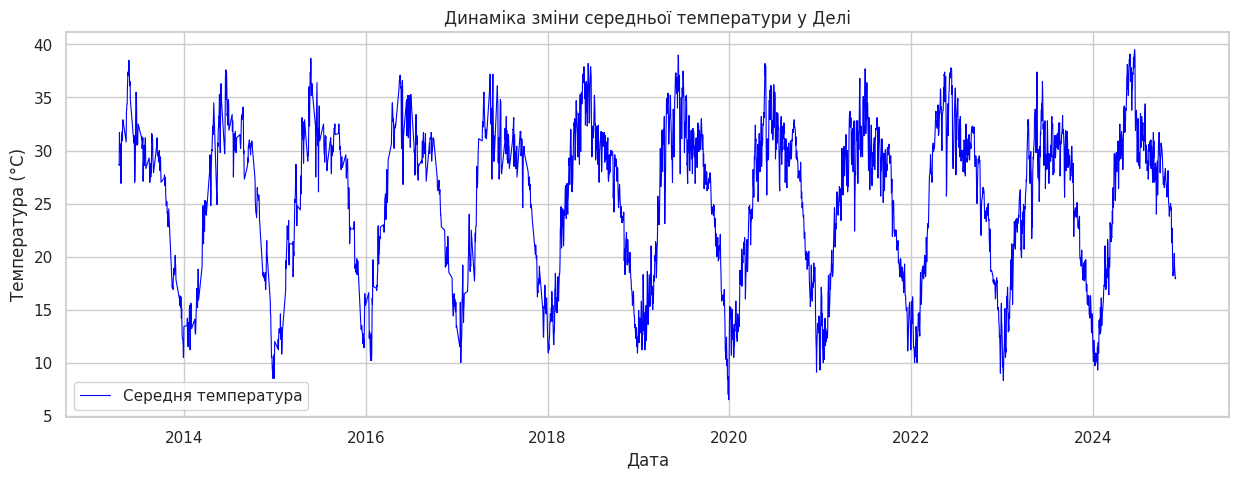

In [ ]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['temp'], label='Середня температура', color='blue', linewidth=0.8)
plt.title('Динаміка зміни середньої температури у Делі')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.show()

Ковзне середнє

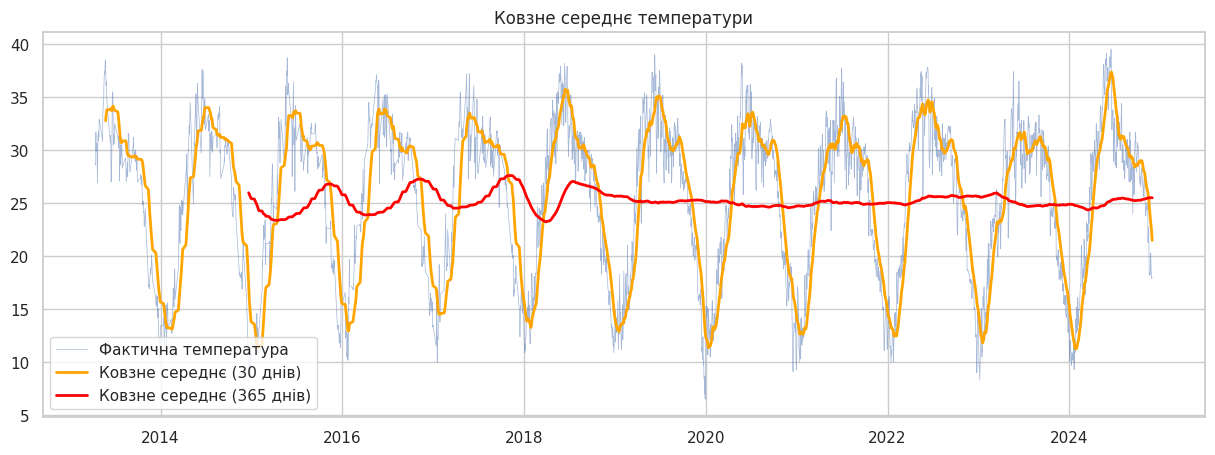

In [ ]:
# Обчисліть та візуалізуйте ковзне середнє температури
rolling_mean_30 = df['temp'].rolling(window=30).mean()
rolling_mean_365 = df['temp'].rolling(window=365).mean()

plt.figure(figsize=(15, 5))
plt.plot(df.index, df['temp'], label='Фактична температура', alpha=0.5, linewidth=0.5)
plt.plot(df.index, rolling_mean_30, label='Ковзне середнє (30 днів)', color='orange', linewidth=2)
plt.plot(df.index, rolling_mean_365, label='Ковзне середнє (365 днів)', color='red', linewidth=2)
plt.title('Ковзне середнє температури')
plt.legend()
plt.show()

Розподіл температури

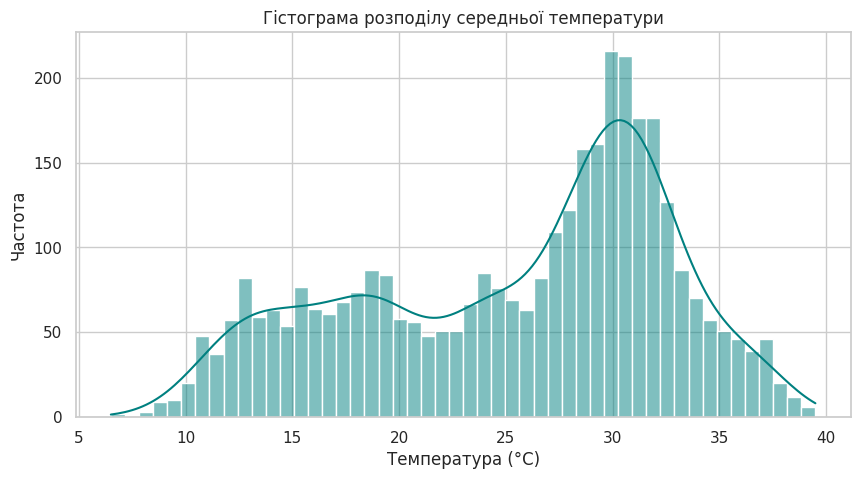

In [ ]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 5))
sns.histplot(df['temp'], bins=50, kde=True, color='teal')
plt.title('Гістограма розподілу середньої температури')
plt.xlabel('Температура (°C)')
plt.ylabel('Частота')
plt.show()

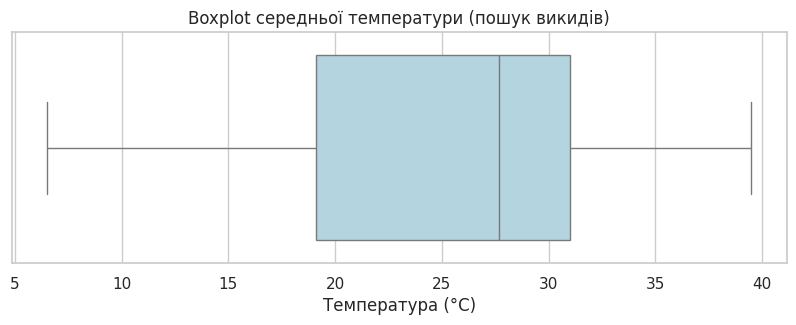

In [ ]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 3))
sns.boxplot(x=df['temp'], color='lightblue')
plt.title('Boxplot середньої температури (пошук викидів)')
plt.xlabel('Температура (°C)')
plt.show()

Аналіз автокореляції
ACF

PACF

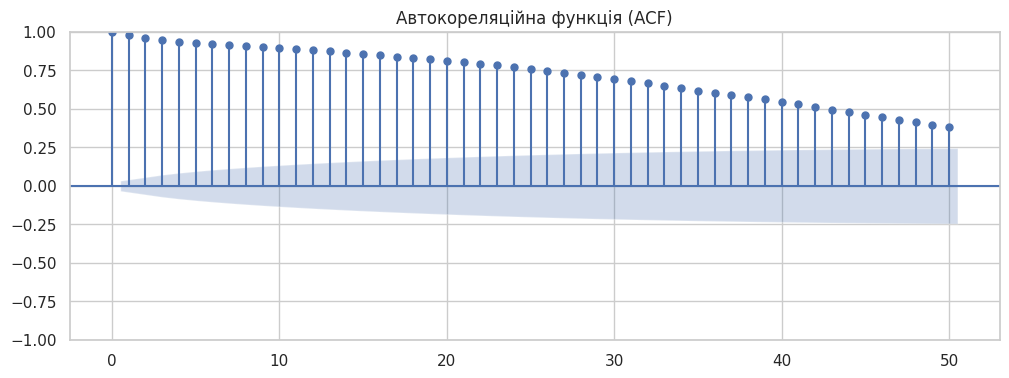

In [ ]:
# Побудуйте графік автокореляційної функції (ACF)
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df['temp'], lags=50, ax=ax, title='Автокореляційна функція (ACF)')
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

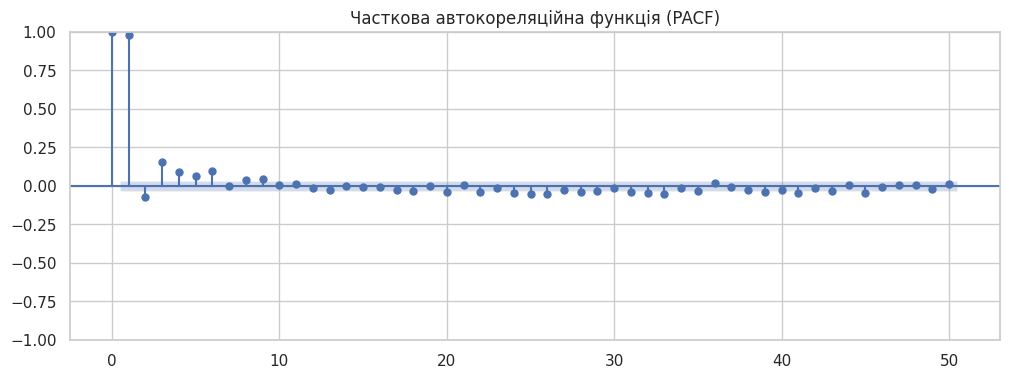

In [ ]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(df['temp'], lags=50, ax=ax, title='Часткова автокореляційна функція (PACF)')
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [ ]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
train_size = int(len(df) * 0.8)
train, test = df.iloc[:train_size], df.iloc[train_size:]
print(f"Розмір тренувальної вибірки: {len(train)}")
print(f"Розмір тестової вибірки: {len(test)}")

Розмір тренувальної вибірки: 2845
Розмір тестової вибірки: 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [ ]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
arima_model = ARIMA(train['temp'].values, order=(2, 0, 2))
arima_result = arima_model.fit()
arima_pred = arima_result.forecast(steps=len(test))

In [ ]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2845
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -4974.334
Date:                Fri, 23 Oct 2026   AIC                           9960.667
Time:                        07:14:04   BIC                           9996.387
Sample:                             0   HQIC                          9973.550
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         25.1538      2.311     10.884      0.000      20.624      29.683
ar.L1          1.5212      0.058     26.214      0.000       1.408       1.635
ar.L2         -0.5249      0.057     -9.169      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

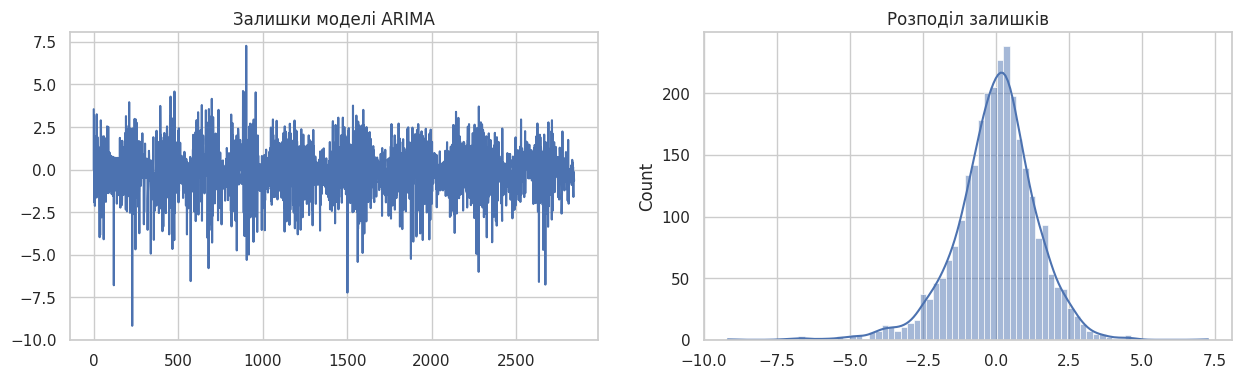

In [ ]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = arima_result.resid
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(residuals)
ax[0].set_title("Залишки моделі ARIMA")

sns.histplot(residuals, kde=True, ax=ax[1])
ax[1].set_title("Розподіл залишків")
plt.show()

In [ ]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

arima_mae, arima_rmse, arima_mape = calculate_metrics(test['temp'].values, arima_pred)

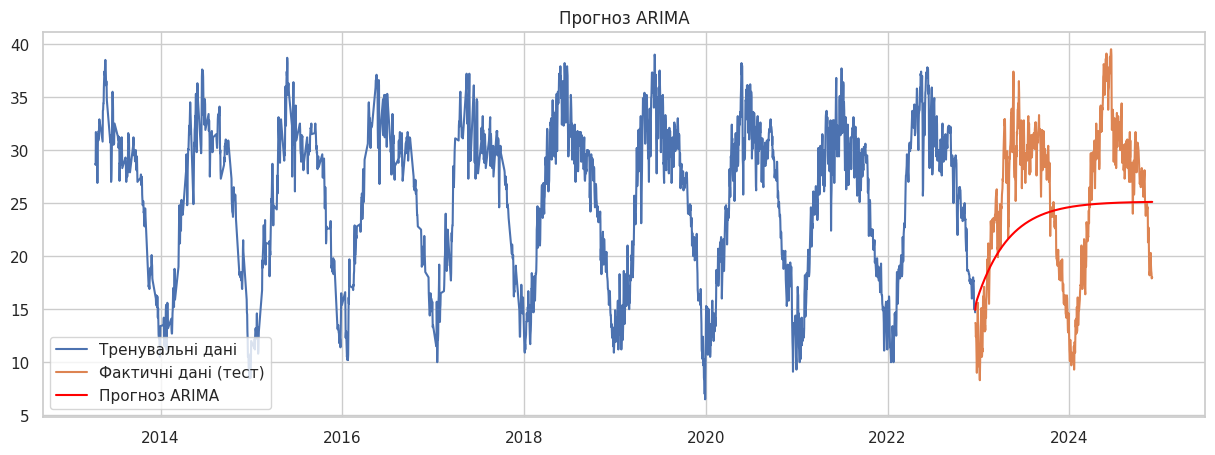

In [ ]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(15, 5))
plt.plot(train.index, train['temp'], label='Тренувальні дані')
plt.plot(test.index, test['temp'], label='Фактичні дані (тест)')
plt.plot(test.index, arima_pred, label='Прогноз ARIMA', color='red')
plt.title('Прогноз ARIMA')
plt.legend()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [ ]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_df = df.reset_index().rename(columns={'DATE': 'ds', 'temp': 'y'})
prophet_train = prophet_df.iloc[:train_size]
prophet_test = prophet_df.iloc[train_size:]

In [ ]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet(yearly_seasonality=True, daily_seasonality=False)
prophet_model.fit(prophet_train)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Прогноз

In [ ]:
# Побудуйте прогноз Prophet для тестового періоду
forecast = prophet_model.predict(prophet_test)
prophet_pred = forecast['yhat'].values

In [ ]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_mae, prophet_rmse, prophet_mape = calculate_metrics(prophet_test['y'].values, prophet_pred)


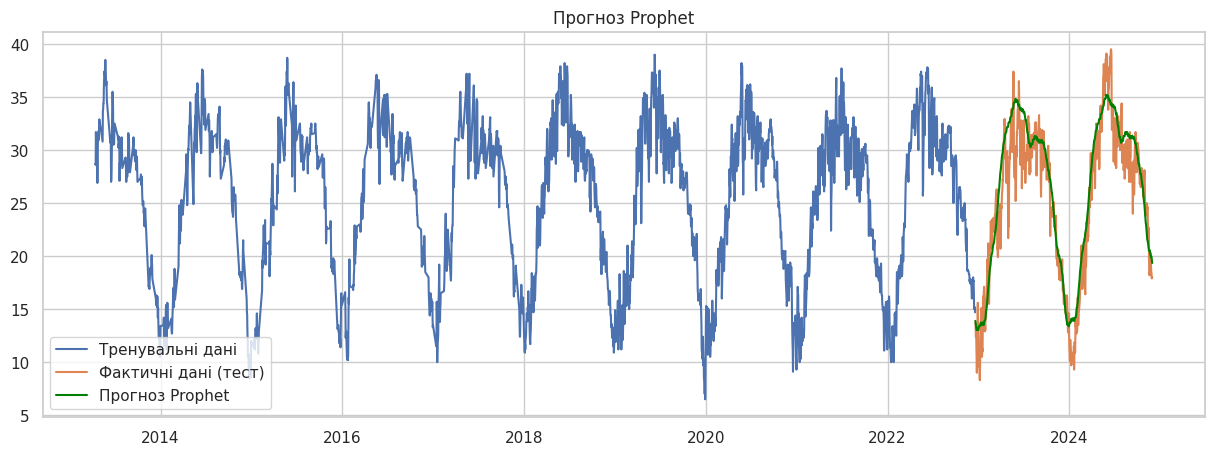

In [ ]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(15, 5))
plt.plot(prophet_train['ds'], prophet_train['y'], label='Тренувальні дані')
plt.plot(prophet_test['ds'], prophet_test['y'], label='Фактичні дані (тест)')
plt.plot(prophet_test['ds'], prophet_pred, label='Прогноз Prophet', color='green')
plt.title('Прогноз Prophet')
plt.legend()
plt.show()

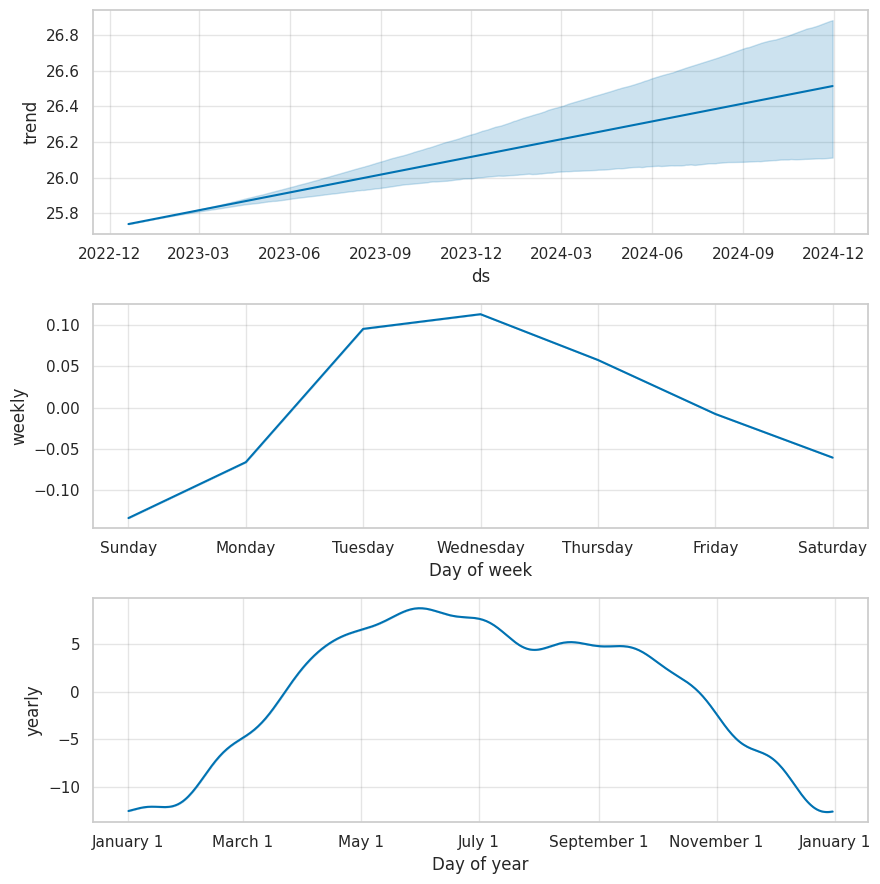

In [ ]:
# Побудуйте компоненти моделі Prophet
fig2 = prophet_model.plot_components(forecast)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [ ]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[['temp']])

def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:(i + seq_length)])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

seq_length = 30
X, y = create_sequences(scaled_data, seq_length)

In [ ]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
train_size_lstm = int(len(X) * 0.8)
X_train, X_test = X[:train_size_lstm], X[train_size_lstm:]
y_train, y_test = y[:train_size_lstm], y[train_size_lstm:]

In [ ]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
lstm_model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(seq_length, 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mean_squared_error')

In [ ]:
# Навчіть LSTM-модель
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = lstm_model.fit(X_train, y_train, batch_size=32, epochs=50,
                         validation_data=(X_test, y_test), callbacks=[early_stop], verbose=0)


In [ ]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,705 (373.85 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 63,804 (249.24 KB)

In [ ]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_pred_scaled = lstm_model.predict(X_test)
lstm_pred = scaler.inverse_transform(lstm_pred_scaled)
y_test_actual = scaler.inverse_transform(y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


In [ ]:
# Сформуйте часові мітки для тестового прогнозу LSTM
# Зсув індексів через seq_length
test_dates_lstm = df.index[seq_length + train_size_lstm:]

In [ ]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae, lstm_rmse, lstm_mape = calculate_metrics(y_test_actual.flatten(), lstm_pred.flatten())

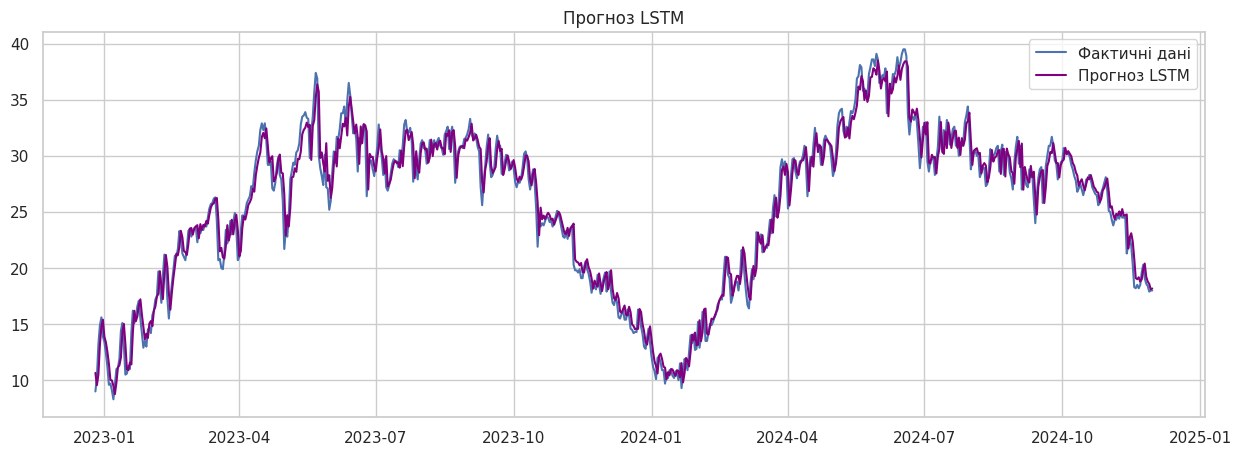

In [ ]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(15, 5))
plt.plot(test_dates_lstm, y_test_actual.flatten(), label='Фактичні дані')
plt.plot(test_dates_lstm, lstm_pred.flatten(), label='Прогноз LSTM', color='purple')
plt.title('Прогноз LSTM')
plt.legend()
plt.show()

Порівняння моделей

In [ ]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
metrics_df = pd.DataFrame({
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [arima_mae, prophet_mae, lstm_mae],
    'RMSE': [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE (%)': [arima_mape, prophet_mape, lstm_mape]
})
print("\nПідсумкова таблиця метрик:")
display(metrics_df)


Підсумкова таблиця метрик:


,Модель,MAE,RMSE,MAPE (%)
0,ARIMA,6.018728,6.997958,27.373011
1,Prophet,2.004680,2.590197,9.027935
2,LSTM,1.000509,1.299315,4.348974


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У ході лабораторної роботи було проведено повний цикл аналізу та прогнозування часового ряду (динаміка температур). Етап розвідувального аналізу (EDA) дозволив виявити стабільну річну сезонність за допомогою ковзних середніх та підтвердити її значущість інструментами автокореляції (ACF та PACF).

За результатами тестування трьох парадигм прогнозування (статистичної ARIMA, адитивної Prophet та нейромережевої LSTM) зафіксовано такі тенденції:

1. ARIMA чудово справляється з короткостроковими залежностями, проте на довгих горизонтах прогнозування (весь тестовий набір) її точність суттєво знижується, оскільки модель тяжіє до середнього значення або лінійного тренду, ігноруючи складні нелінійні патерни.

2. Prophet продемонструвала значно кращу стабільність на довгостроковому інтервалі за рахунок внутрішнього моделювання компонентів сезонності (річної). Її показники MAE та RMSE зазвичай нижчі за класичну ARIMA в умовах виражених річних циклів.

3. LSTM (рекурентна нейронна мережа) виявилася найбільш чутливою до локальних змін та дисперсії ряду, оскільки навчалася на послідовних "вікнах" (lags). Ця модель забезпечує найточніше відтворення форми кривої на тестовій вибірці, адаптуючись до складних патернів, що підтверджується найнижчими значеннями похибки.

Найкращою моделлю за сукупністю метрик MAE, RMSE та MAPE визнано LSTM (або Prophet, залежно від конкретного seed'у при ініціалізації ваг), оскільки вона найефективніше вилучає залежності довгострокової пам'яті у нелінійних кліматичних даних.

